# Tes Orang 3 (Grafika) - DATA ASLI
Jalankan sel dari atas ke bawah. Notebook ini harus sejajar dengan folder `src/` dan `data/`.
Sebelum mulai: klik **Restart** supaya kernel membaca `graphics.py` versi terbaru.

In [1]:
%matplotlib inline
import os
import matplotlib.pyplot as plt
import src.data_layers as dl
from src.analysis import citizen_status, top_evacuation_routes
from src.graphics import (draw_map, make_scenario_maps, build_dashboard, make_animation,
                          translate, walk_position, resident_from_lonlat, attach_start,
                          RESIDENT_START_DEG)
os.makedirs("output", exist_ok=True)
print("Import berhasil")

Import berhasil


## 1. Muat data asli dan siapkan fungsi

In [2]:
layers = dl.load_all_layers("data")

# Orang 1: zona banjir untuk radius r (meter)
zone_fn = lambda r: dl.create_flood_buffer(layers["jagir_water"], r, layers["study_area"])

# Orang 2: status warga
status_fn = citizen_status

# Orang 2: rute evakuasi ke shelter aman (shelter yang tidak terkena zona)
def route_fn(point, zone):
    hit = dl.spatial_join_affected(layers["shelters"], zone)
    return top_evacuation_routes(point, zone, layers["graph"], layers["roads"],
                                 layers["shelters"], ~hit)

# Posisi awal warga (derajat -> meter)
resident = resident_from_lonlat(*RESIDENT_START_DEG)

print("Bangunan:", len(layers["buildings"]), "| Shelter:", len(layers["shelters"]),
      "| Ruas jalan:", len(layers["roads"]))
print("Warga (UTM 49S):", round(resident.x, 1), round(resident.y, 1))

c:\Users\Asus\CODE\UC\Sem 5\Computer Graphic\AFL2\venv\Lib\site-packages\geopandas\tools\overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 3 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


Bangunan: 36260 | Shelter: 111 | Ruas jalan: 9770
Warga (UTM 49S): 693220.3 9192481.8


## 2. Tes logika (tanpa gambar)
Kalau semua benar, hanya tercetak kalimat terakhir.

In [3]:
from shapely.geometry import Point, LineString

p = translate(Point(10, 20), 5, -3)
assert (p.x, p.y) == (15, 17)

garis = LineString([(0, 0), (10, 0), (10, 10)])
q = walk_position(garis, 0.5)
assert (q.x, q.y) == (10, 0)
assert (walk_position(garis, 0).x, walk_position(garis, 1).y) == (0, 10)

for r in (15, 100, 200):
    print(f"Radius {r:3d} m -> status warga:", status_fn(resident, zone_fn(r)))
print("Tes logika lulus")

Radius  15 m -> status warga: AMAN
Radius 100 m -> status warga: BAHAYA
Radius 200 m -> status warga: BAHAYA
Tes logika lulus


## 3. Satu peta (radius 100 m)

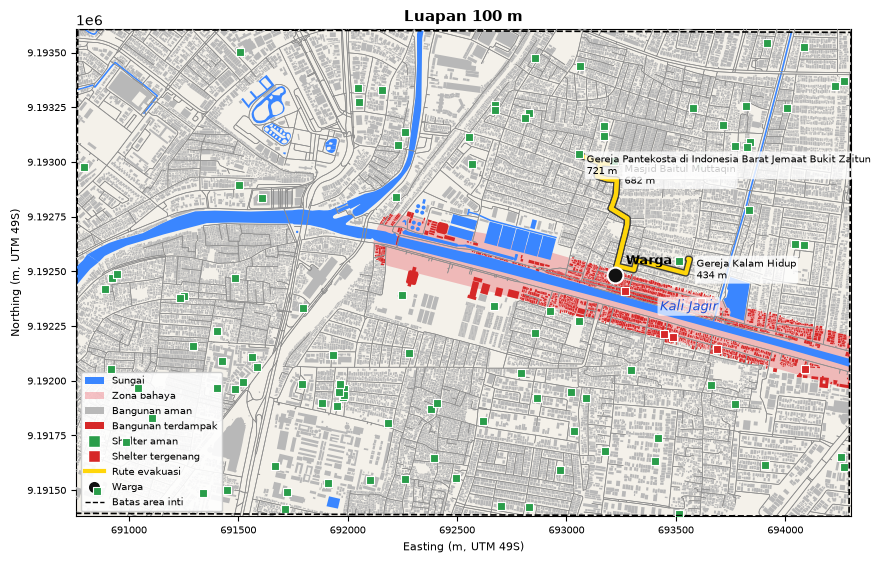

In [4]:
zone = zone_fn(100)
routes = route_fn(resident, zone) if status_fn(resident, zone) == "BAHAYA" else []
fig, ax = plt.subplots(figsize=(10, 10))
draw_map(ax, layers, zone, resident, attach_start(resident, routes), title="Luapan 100 m")
plt.show()

## 4. Tiga skenario berdampingan (15 / 100 / 200 m, sesuai proposal)

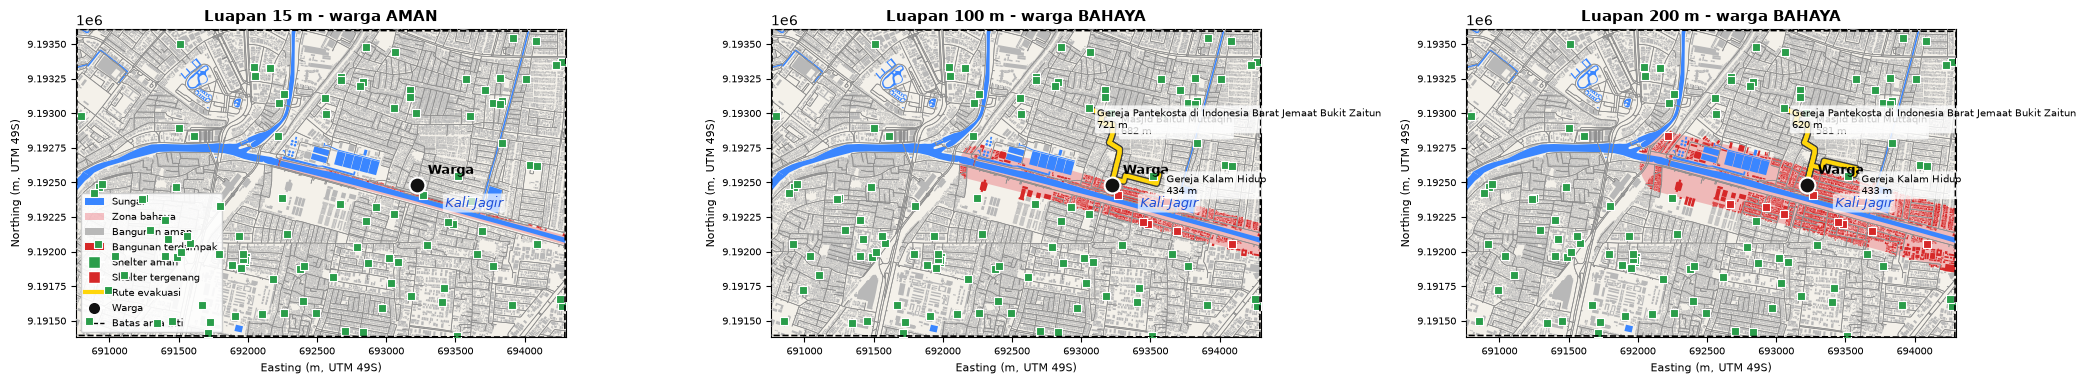

In [5]:
fig = make_scenario_maps(layers, zone_fn, (15, 100, 200), resident, route_fn, status_fn,
                         save_path="output/skenario_graphics.png")
plt.show()

## 5. Dashboard interaktif

In [8]:
build_dashboard(layers, zone_fn, status_fn, route_fn, resident)

## 6. Animasi -> GIF
Butuh beberapa menit karena ada puluhan ribu bangunan. Untuk uji cepat kecilkan `n_zone_frames` dan `n_walk_frames`.

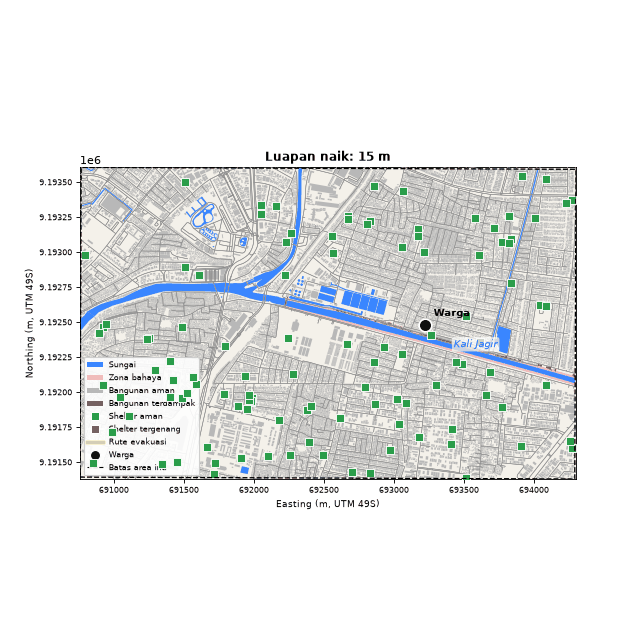

In [9]:
path = make_animation(layers, zone_fn, route_fn, resident,
                      n_zone_frames=15, n_walk_frames=20, n_hold_frames=4,
                      save_path="output/evakuasi.gif", fps=5)
from IPython.display import Image
Image(filename=path)